# Step 1. Data Profiling & Understanding
## Moneyball 2.0 — FIFA 23 и Transfermarkt

**Цель:** установить фактический размер и состав данных, оценить качество, доступные периоды и возможность объединения.

В notebook проверяются все 19 CSV из трёх предоставленных архивов. Количество записей отделяется от количества уникальных игроков, а история обновлений — от одного исторического среза.

**Основной срез:** FIFA 23, мужчины, **26.09.2022**. CM — точный токен `CM` среди позиций. Женские данные анализируются отдельно. Для контроля также рассматривается последнее доступное обновление FIFA 23 на **13.01.2023**.

План: источники и воспроизводимость → размеры и схемы → пропуски и дубликаты → игроки и CM → даты и сезоны → entity matching → историческая стоимость → покрытие и смещение → Feature Set v1 → итоговые проверки.

**Граница этапа:** это profiling и проверка пригодности данных. Модели здесь не обучаются; высокое сходство и ценовые остатки не объявляются доказательством успешного трансфера.


### 1. Окружение и параметры

Запустить ядро Python и выполнить **Run All**. Зависимости: `pip install -r requirements-notebooks.txt` из корня проекта.

- По умолчанию архивы ищутся в `data/raw/`, затем в `~/Downloads`. Другой каталог можно указать переменной `MONEYBALL_DATA_DIR`.
- `RUN_FULL_PROFILE=False`: использовать результаты **предыдущего полного прохода**, проверив SHA-256 исходных ZIP, CRC32/схемы всех CSV и суммы срезов. Это не выборочная оценка размеров.
- `RECHECK_SMALL_FILES=True`: дополнительно пересчитать строки и пустые поля 18 CSV стандартным CSV-парсером. Большой `male_players.csv` повторно не распаковывается: его неизменность подтверждает SHA-256 архива, а итоги сверяются по 558 срезам.
- `RUN_FULL_PROFILE=True`: заново выполнить полный потоковый profiling всех 19 CSV, включая мужской файл 5,6 ГБ. Этот режим занимает несколько минут и обновляет локальные профили.

Код схем, совпадений и датированных объединений находится в `scripts/`; notebook повторно выполняет проверки на исходных таблицах и явно показывает использованные функции.


In [1]:
from pathlib import Path
from collections import Counter
import csv
import hashlib
import io
import json
import os
import platform
import subprocess
import sys
import zipfile

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline

def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "config/feature_set_v1.json").exists() and (candidate / "scripts").is_dir():
            return candidate
    raise FileNotFoundError("Запустите notebook из notebooks/ или корня football-moneyball-ai.")

ROOT = find_project_root()
REPORTS = ROOT / "reports/data_profiling"
PROCESSED = ROOT / "data/processed/profiling"
FIGURES = PROCESSED / "notebook_figures"
FIGURES.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "scripts"))

RUN_FULL_PROFILE = False
RECHECK_SMALL_FILES = True
CUTOFF = "2022-09-26"
EXTRACT_ANCHOR = "2025-09-13"  # observed end of club-table modification dates
RANDOM_SEED = 42

pd.set_option("display.max_columns", 35)
pd.set_option("display.max_rows", 30)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.labelsize": 10})
COLORS = {"male": "#264653", "female": "#9b5e80", "tm": "#2a9d8f", "warning": "#e9c46a", "loss": "#e76f51"}
figure_paths = []

def show_figure(fig, name):
    path = FIGURES / f"{name}.png"
    fig.savefig(path, dpi=135, bbox_inches="tight", facecolor="white")
    figure_paths.append(path)
    plt.show()
    plt.close(fig)

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

display(pd.DataFrame({"компонент": ["Python", "pandas", "numpy", "matplotlib"],
                      "версия": [platform.python_version(), pd.__version__, np.__version__, matplotlib.__version__]}))


,компонент,версия
0,Python,3.12.0
1,pandas,3.0.6
2,numpy,2.2.0
3,matplotlib,3.10.0


In [2]:
from profile_moneyball_data import ARCHIVES

search_dirs = ([Path(os.environ["MONEYBALL_DATA_DIR"])] if os.environ.get("MONEYBALL_DATA_DIR") else [])
search_dirs += [ROOT / "data/raw", Path.home() / "Downloads"]
archive_paths = {}
for source, filename in ARCHIVES.items():
    archive_paths[source] = next((folder / filename for folder in search_dirs if (folder / filename).is_file()), None)
    if archive_paths[source] is None:
        raise FileNotFoundError(f"Нет {filename}. Укажите MONEYBALL_DATA_DIR или поместите архив в data/raw/.")

if RUN_FULL_PROFILE:
    for source, archive_path in archive_paths.items():
        subprocess.run([sys.executable, str(ROOT / "scripts/profile_moneyball_data.py"),
                        "--source", source, "--downloads", str(archive_path.parent)], cwd=ROOT, check=True)

manifests = {}
archive_checks = []
for source, archive_path in archive_paths.items():
    manifest_path = REPORTS / f"{source}_archive.json"
    if not manifest_path.exists():
        raise FileNotFoundError("Нет полного профиля. Установите RUN_FULL_PROFILE=True и выполните notebook заново.")
    manifest = read_json(manifest_path)
    digest = hashlib.sha256()
    with archive_path.open("rb") as file:
        for block in iter(lambda: file.read(8 * 1024 * 1024), b""):
            digest.update(block)
    assert digest.hexdigest() == manifest["sha256"], f"Архив изменился: {archive_path.name}; нужен новый полный profiling."
    assert archive_path.stat().st_size == manifest["bytes"]
    manifests[source] = manifest
    archive_checks.append({"источник": source, "архив": archive_path.name,
                           "размер_МБ": round(archive_path.stat().st_size / 1e6, 2),
                           "дата_полного_аудита": manifest["profile_date"], "SHA256": "совпадает"})
display(pd.DataFrame(archive_checks))


,источник,архив,размер_МБ,дата_полного_аудита,SHA256
0,fifa_female,stefanoleone992_fifa-23-complete-player-datase...,26.56,2026-11-07,совпадает
1,fifa_male,stefanoleone992_fifa-23-complete-player-datase...,1620.60,2026-11-07,совпадает
2,transfermarkt,xfkzujqjvx97n_football-datasets_data.zip,85.31,2026-11-07,совпадает


### 2. Реальные размеры, единицы наблюдения и доступные столбцы

**FIFA players:** игрок × версия FIFA × обновление. **TM profiles:** профиль игрока. **TM market value:** игрок × дата оценки. **TM performances:** игрок × сезон × соревнование × команда. Сумма строк этих таблиц не равна числу футболистов.

`legacy` — по одному годовому срезу для каждой версии FIFA. Его нельзя просто добавить к полной таблице как новых игроков.


In [3]:
profiles = []
schemas = {}
column_frames = []
for source in ARCHIVES:
    profiles.extend(read_json(REPORTS / f"{source}_profiles.json"))
    schemas[source] = read_json(REPORTS / f"{source}_schemas.json")
    column_frames.append(pd.read_csv(REPORTS / f"{source}_columns.csv"))
assert len(profiles) == 19
profile_by_file = {p["file"]: p for p in profiles}
columns_audit = pd.concat(column_frames, ignore_index=True)

# Current archive headers and CRC32 must match the fully scanned files.
for source, archive_path in archive_paths.items():
    with zipfile.ZipFile(archive_path) as archive:
        for profile in [p for p in profiles if p["source"] == source]:
            member = archive.getinfo(profile["member"])
            assert f"{member.CRC:08x}" == profile["zip_crc32"]
            assert member.file_size == profile["uncompressed_bytes"]
            with io.TextIOWrapper(archive.open(member), encoding="utf-8-sig", newline="") as file:
                header = next(csv.reader(file))
            assert header == schemas[source][profile["file"]]
            assert len(header) == profile["columns"]
            assert sum(profile["missing_by_column"].values()) == profile["missing_cells"]

inventory = pd.DataFrame([{k: p[k] for k in ["source", "file", "rows", "columns", "missing_cells", "missing_pct", "duplicate_rows_hash"]}
                          for p in profiles]).sort_values(["source", "file"]).reset_index(drop=True)
display(inventory.round({"missing_pct": 2}))
print(f"Всего записей в 19 CSV: {inventory.rows.sum():,}; пустых ячеек: {inventory.missing_cells.sum():,}.")


Всего записей в 19 CSV: 16,487,119; пустых ячеек: 89,219,995.


,source,file,rows,columns,missing_cells,missing_pct,duplicate_rows_hash
0,fifa_female,female_coaches.csv,52,8,55,13.22,0
1,fifa_female,female_players (legacy).csv,3196,110,46602,13.26,0
2,fifa_female,female_players.csv,181361,110,2883528,14.45,0
3,fifa_female,female_teams.csv,7941,54,115261,26.88,0
4,fifa_male,male_coaches.csv,1155,8,888,9.61,0
5,fifa_male,male_players (legacy).csv,161583,110,1218702,6.86,0
6,fifa_male,male_players.csv,10003590,110,75828244,6.89,0
7,fifa_male,male_teams.csv,385055,54,4172566,20.07,0
8,transfermarkt,player_injuries.csv,143195,7,1567,0.16,111
9,transfermarkt,player_latest_market_value.csv,69441,3,0,0.00,0


In [4]:
# Independent recount through Python csv, not pandas. No estimates from file size.
independent_counts = []
if RECHECK_SMALL_FILES:
    for source, archive_path in archive_paths.items():
        with zipfile.ZipFile(archive_path) as archive:
            for profile in [p for p in profiles if p["source"] == source]:
                if profile["file"] == "male_players.csv":
                    continue
                rows = empty = 0
                with io.TextIOWrapper(archive.open(profile["member"]), encoding="utf-8-sig", newline="") as file:
                    reader = csv.reader(file)
                    header = next(reader)
                    for row in reader:
                        if not row:
                            continue
                        assert len(row) == len(header), (profile["file"], rows)
                        rows += 1
                        empty += row.count("")
                assert (rows, len(header), empty) == (profile["rows"], profile["columns"], profile["missing_cells"])
                independent_counts.append({"file": profile["file"], "rows": rows, "missing_cells": empty, "check": "PASS"})
    display(pd.DataFrame(independent_counts))
    assert len(independent_counts) == 18
else:
    print("Независимый пересчёт 18 CSV отключён параметром; использован SHA-проверенный полный профиль.")

snapshot_tables = {}
for profile in profiles:
    if "snapshot_count" not in profile:
        continue
    filename = profile["file"][:-4].replace(" ", "_") + "_snapshots.csv"
    snapshots = pd.read_csv(REPORTS / filename)
    assert len(snapshots) == profile["snapshot_count"]
    assert snapshots.rows.sum() == profile["rows"]
    if "cm_rows" in profile:
        assert snapshots.cm_rows.sum() == profile["cm_rows"]
        assert snapshots.primary_cm_rows.sum() == profile["primary_cm_rows"]
    snapshot_tables[profile["file"]] = snapshots
print("Суммы всех срезов сверены; большой male_players.csv: 10 003 590 строк, 558 срезов.")


Суммы всех срезов сверены; большой male_players.csv: 10 003 590 строк, 558 срезов.


,file,rows,missing_cells,check
0,female_coaches.csv,52,55,PASS
1,female_players (legacy).csv,3196,46602,PASS
2,female_players.csv,181361,2883528,PASS
3,female_teams.csv,7941,115261,PASS
4,male_players (legacy).csv,161583,1218702,PASS
5,male_teams.csv,385055,4172566,PASS
6,male_coaches.csv,1155,888,PASS
7,player_injuries.csv,143195,1567,PASS
8,player_latest_market_value.csv,69441,0,PASS
9,player_market_value.csv,901429,0,PASS


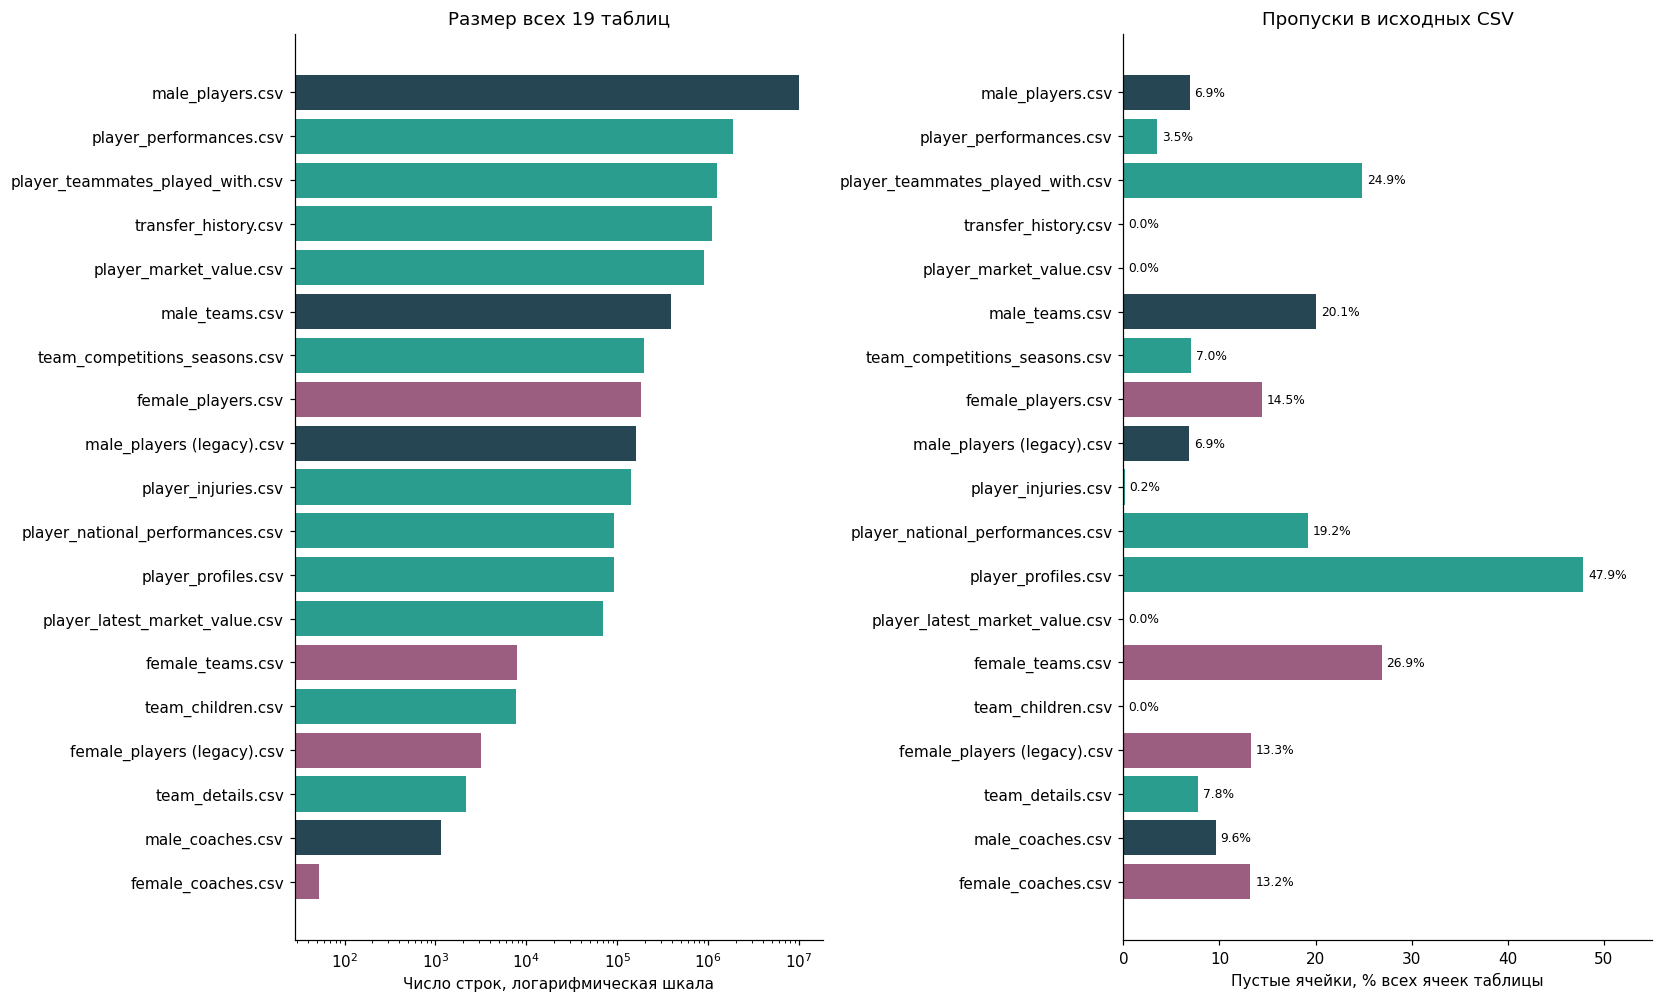

In [5]:
ordered = inventory.sort_values("rows")
fig, axes = plt.subplots(1, 2, figsize=(15, 9), layout="constrained")
bar_colors = [COLORS["male"] if s == "fifa_male" else COLORS["female"] if s == "fifa_female" else COLORS["tm"] for s in ordered.source]
axes[0].barh(ordered.file, ordered.rows, color=bar_colors)
axes[0].set_xscale("log")
axes[0].set_xlabel("Число строк, логарифмическая шкала")
axes[0].set_title("Размер всех 19 таблиц")
axes[1].barh(ordered.file, ordered.missing_pct, color=bar_colors)
axes[1].set_xlim(0, 55)
axes[1].set_xlabel("Пустые ячейки, % всех ячеек таблицы")
axes[1].set_title("Пропуски в исходных CSV")
for index, value in enumerate(ordered.missing_pct):
    axes[1].text(value + .5, index, f"{value:.1f}%", va="center", fontsize=8)
show_figure(fig, "01_sizes_and_missingness")


In [6]:
schema_records = [{"source": source, "file": filename, "ordinal": i + 1, "column": column}
                  for source, tables in schemas.items() for filename, fields in tables.items()
                  for i, column in enumerate(fields)]
schema_table = pd.DataFrame(schema_records)
assert len(schema_table) == inventory["columns"].sum()
display(pd.DataFrame([{"source": s, "file": f, "n_columns": len(fields), "columns": ", ".join(fields)}
                      for s, tables in schemas.items() for f, fields in tables.items()]))

# Print every distinct schema in full; the summary table above uses a compact preview.
# Male/female/legacy player schemas and latest/history value schemas are identical.
schema_groups = {}
for source, tables in schemas.items():
    for filename, fields in tables.items():
        schema_groups.setdefault(tuple(fields), []).append(f"{source}/{filename}")
for fields, filenames in schema_groups.items():
    print(f"\n{'; '.join(filenames)} ({len(fields)} столбцов):")
    for offset in range(0, len(fields), 6):
        print("  " + ", ".join(fields[offset:offset+6]))

all_names = set(schema_table.column.str.casefold())
unavailable = ["xg", "xa", "progressive_passes", "progressive_carries", "pressures", "pass_completion"]
assert not set(unavailable) & all_names
print("\nВ схеме нет:", ", ".join(unavailable))



fifa_female/female_coaches.csv; fifa_male/male_coaches.csv (8 столбцов):
  coach_id, coach_url, short_name, long_name, dob, nationality_id
  nationality_name, face_url

fifa_female/female_players (legacy).csv; fifa_female/female_players.csv; fifa_male/male_players (legacy).csv; fifa_male/male_players.csv (110 столбцов):
  player_id, player_url, fifa_version, fifa_update, fifa_update_date, short_name
  long_name, player_positions, overall, potential, value_eur, wage_eur
  age, dob, height_cm, weight_kg, league_id, league_name
  league_level, club_team_id, club_name, club_position, club_jersey_number, club_loaned_from
  club_joined_date, club_contract_valid_until_year, nationality_id, nationality_name, nation_team_id, nation_position
  nation_jersey_number, preferred_foot, weak_foot, skill_moves, international_reputation, work_rate
  body_type, real_face, release_clause_eur, player_tags, player_traits, pace
  shooting, passing, dribbling, defending, physic, attacking_crossing
  attackin

,source,file,n_columns,columns
0,fifa_female,female_coaches.csv,8,"coach_id, coach_url, short_name, long_name, do..."
1,fifa_female,female_players (legacy).csv,110,"player_id, player_url, fifa_version, fifa_upda..."
2,fifa_female,female_players.csv,110,"player_id, player_url, fifa_version, fifa_upda..."
3,fifa_female,female_teams.csv,54,"team_id, team_url, fifa_version, fifa_update, ..."
4,fifa_male,male_players (legacy).csv,110,"player_id, player_url, fifa_version, fifa_upda..."
5,fifa_male,male_teams.csv,54,"team_id, team_url, fifa_version, fifa_update, ..."
6,fifa_male,male_players.csv,110,"player_id, player_url, fifa_version, fifa_upda..."
7,fifa_male,male_coaches.csv,8,"coach_id, coach_url, short_name, long_name, do..."
8,transfermarkt,player_injuries.csv,7,"player_id, season_name, injury_reason, from_da..."
9,transfermarkt,player_latest_market_value.csv,3,"player_id, date_unix, value"


### 3. Пропуски, маркеры неизвестного значения и числовое качество

В основной сводке пропуск — **пустое CSV-поле**, а не любой ноль. `N/A` и `-` нужно считать отдельно. Нулевой рост физически невозможен; нулевая рыночная оценка — записанный ноль, который нельзя автоматически назвать ценой бесплатного трансфера.

Пропуски часто структурные: у полевых игроков не заполнена скорость вратаря, у части женских записей отсутствует клубная/финансовая информация. Удаление строк по всем 110 столбцам уничтожило бы полезные наблюдения.


In [7]:
def read_source(source, filename, **kwargs):
    profile = next(p for p in profiles if p["source"] == source and p["file"] == filename)
    with zipfile.ZipFile(archive_paths[source]) as archive:
        return pd.read_csv(archive.open(profile["member"]), dtype=str, na_filter=False, **kwargs)

tm_profiles = read_source("transfermarkt", "player_profiles.csv")
values = read_source("transfermarkt", "player_market_value.csv")
latest_values = read_source("transfermarkt", "player_latest_market_value.csv")
assert tm_profiles.player_id.is_unique
assert not values.duplicated(["player_id", "date_unix"]).any()

semantic_missing = []
for column in ["height", "foot", "citizenship", "place_of_birth", "date_of_birth"]:
    empty = tm_profiles[column].eq("")
    marker = tm_profiles[column].isin(["N/A", "NA", "NULL", "null", "None", "NaN", "nan", "-", "?"])
    invalid_zero = pd.to_numeric(tm_profiles[column], errors="coerce").eq(0) if column == "height" else pd.Series(False, index=tm_profiles.index)
    semantic_missing.append({"field": column, "empty": int(empty.sum()), "unknown_marker": int(marker.sum()),
                             "invalid_zero": int(invalid_zero.sum()), "unusable_pct": 100 * (empty | marker | invalid_zero).mean()})
display(pd.DataFrame(semantic_missing).round(2))

display(columns_audit.loc[columns_audit.source.eq("transfermarkt") & columns_audit.missing.gt(0),
                         ["file", "column", "missing", "missing_pct"]].sort_values("missing_pct", ascending=False).head(25))
print("Нулевых исторических оценок:", pd.to_numeric(values.value).eq(0).sum())


Нулевых исторических оценок: 48009


,field,empty,unknown_marker,invalid_zero,unusable_pct
0,height,4,0,18867,20.36
1,foot,21790,1698,0,25.35
2,citizenship,28,29,0,0.06
3,place_of_birth,16633,51,0,18.00
4,date_of_birth,1006,0,0,1.09


,file,column,missing,missing_pct
582,player_national_performances.csv,debut,92701,100.000000
638,player_profiles.csv,fourth_club_name,92670,99.998921
637,player_profiles.csv,fourth_club_url,92670,99.998921
635,player_profiles.csv,third_club_url,92629,99.954678
636,player_profiles.csv,third_club_name,92629,99.954678
639,player_profiles.csv,date_of_death,92399,99.706489
633,player_profiles.csv,second_club_url,91693,98.944654
634,player_profiles.csv,second_club_name,91693,98.944654
632,player_profiles.csv,contract_there_expires,90165,97.295810
628,player_profiles.csv,contract_option,89100,96.146583


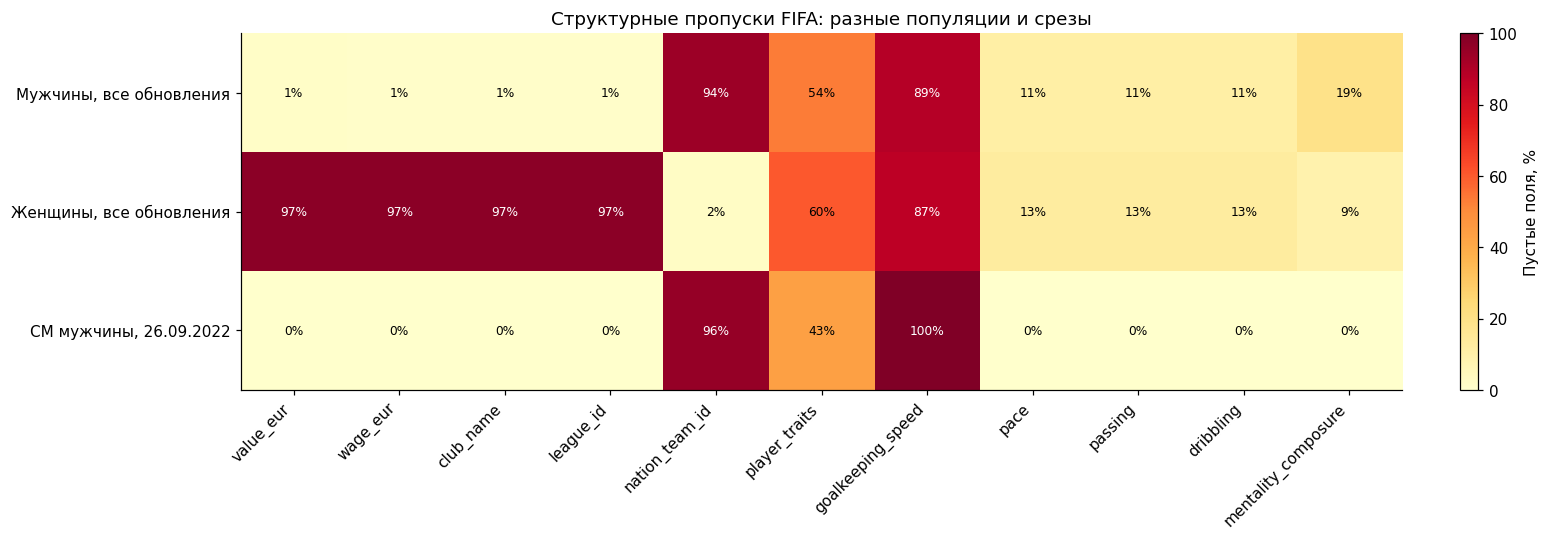

In [8]:
male_legacy = read_source("fifa_male", "male_players (legacy).csv")
female_legacy = read_source("fifa_female", "female_players (legacy).csv")
male_release = male_legacy.loc[male_legacy.fifa_version.eq("23")].copy()
female_release = female_legacy.loc[female_legacy.fifa_version.eq("23")].copy()

def cm_mask(frame):
    return frame.player_positions.str.split(",").apply(lambda parts: "CM" in [p.strip() for p in parts])

def primary_cm_mask(frame):
    return frame.player_positions.str.split(",").str[0].str.strip().eq("CM")

cm_release = male_release.loc[cm_mask(male_release)].copy()
fields = ["value_eur", "wage_eur", "club_name", "league_id", "nation_team_id", "player_traits", "goalkeeping_speed",
          "pace", "passing", "dribbling", "mentality_composure"]
missing_matrix = pd.DataFrame({
    "Мужчины, все обновления": [100 * profile_by_file["male_players.csv"]["missing_by_column"][f] / profile_by_file["male_players.csv"]["rows"] for f in fields],
    "Женщины, все обновления": [100 * profile_by_file["female_players.csv"]["missing_by_column"][f] / profile_by_file["female_players.csv"]["rows"] for f in fields],
    "CM мужчины, 26.09.2022": [100 * cm_release[f].eq("").mean() for f in fields],
}, index=fields).T
fig, ax = plt.subplots(figsize=(14, 4.8), layout="constrained")
image = ax.imshow(missing_matrix, vmin=0, vmax=100, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(fields)), fields, rotation=45, ha="right")
ax.set_yticks(range(len(missing_matrix)), missing_matrix.index)
for i in range(len(missing_matrix)):
    for j in range(len(fields)):
        value = missing_matrix.iloc[i, j]
        ax.text(j, i, f"{value:.0f}%", ha="center", va="center", color="white" if value > 65 else "black", fontsize=8)
fig.colorbar(image, ax=ax, label="Пустые поля, %")
ax.set_title("Структурные пропуски FIFA: разные популяции и срезы")
show_figure(fig, "02_structural_missingness")


### 4. Дубликаты и целостность связей

Полные профили содержат 64-битные отпечатки строк и ключей. Для таблиц с обнаруженными повторами ниже дополнительно используется **точное** `DataFrame.duplicated()`.

Не следует выполнять inner join всех таблиц подряд: это незаметно исключит футболистов без профиля или истории травм. Перед соединением таблиц «один ко многим» требуется агрегация до нужной единицы наблюдения.


,file,rows,exact_duplicates,unique_rows,duplicate_key_rows
0,player_injuries.csv,143195,111,143084,111.0
1,player_national_performances.csv,92701,32,92669,69.0
2,team_competitions_seasons.csv,196378,143359,53019,143359.0
3,transfer_history.csv,1101440,123,1101317,NaN


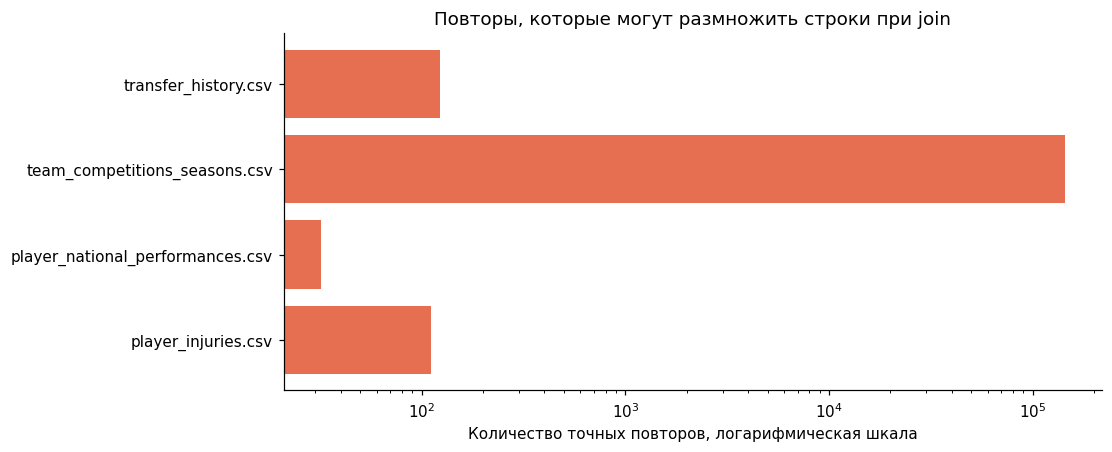

In [9]:
duplicates = []
for filename in ["player_injuries.csv", "player_national_performances.csv", "team_competitions_seasons.csv", "transfer_history.csv"]:
    frame = read_source("transfermarkt", filename)
    profile = profile_by_file[filename]
    exact = int(frame.duplicated().sum())
    assert exact == profile["duplicate_rows_hash"]
    key = profile["key"]
    key_duplicates = int(frame.duplicated(key).sum()) if key else None
    if key:
        assert key_duplicates == profile["duplicate_key_rows_hash"]
    duplicates.append({"file": filename, "rows": len(frame), "exact_duplicates": exact,
                       "unique_rows": len(frame) - exact, "duplicate_key_rows": key_duplicates})
    del frame
duplicates = pd.DataFrame(duplicates)
display(duplicates)

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.barh(duplicates.file, duplicates.exact_duplicates, color=COLORS["loss"])
ax.set_xscale("log")
ax.set_xlabel("Количество точных повторов, логарифмическая шкала")
ax.set_title("Повторы, которые могут размножить строки при join")
show_figure(fig, "03_exact_duplicates")


In [10]:
profile_ids = set(tm_profiles.player_id)
integrity = []
for filename in ["player_injuries.csv", "player_market_value.csv", "player_latest_market_value.csv",
                 "player_national_performances.csv", "player_performances.csv",
                 "player_teammates_played_with.csv", "transfer_history.csv"]:
    identifiers = read_source("transfermarkt", filename, usecols=["player_id"])["player_id"]
    observed_ids = set(identifiers)
    integrity.append({"file": filename, "unique_player_ids": len(observed_ids),
                      "ids_without_profile": len(observed_ids - profile_ids),
                      "rows_without_profile": int((~identifiers.isin(profile_ids)).sum())})
integrity = pd.DataFrame(integrity)
reference_integrity = pd.read_csv(REPORTS / "referential_integrity.csv")
assert integrity.set_index("file").rows_without_profile.to_dict() == reference_integrity.set_index("file").rows_without_profile.to_dict()
display(integrity)


,file,unique_player_ids,ids_without_profile,rows_without_profile
0,player_injuries.csv,34561,0,0
1,player_market_value.csv,69441,0,0
2,player_latest_market_value.csv,69441,0,0
3,player_national_performances.csv,36339,8189,17892
4,player_performances.csv,88375,0,0
5,player_teammates_played_with.csv,84401,0,0
6,transfer_history.csv,117944,26733,262140


### 5. Сколько футболистов и центральных полузащитников

В полном FIFA-файле один игрок наблюдается многократно. `CM` должен совпадать с отдельным токеном: наличие `CAM` или `CDM` само по себе не означает попадание в выборку CM.

Текущая позиция TM относится к более позднему состоянию профиля. Её не используем для переопределения исторической FIFA-выборки. Явного поля пола в TM profiles нет.


In [11]:
population = []
for filename in ["male_players.csv", "male_players (legacy).csv", "female_players.csv", "female_players (legacy).csv"]:
    p = profile_by_file[filename]
    population.append({"file": filename, "observations": p["rows"], "unique_players": p["unique_ids"]["player_id"],
                       "cm_observations": p["cm_rows"], "unique_cm_any_version": p["cm_unique_players"],
                       "unique_primary_cm_any_version": p["primary_cm_unique_players"]})
display(pd.DataFrame(population))

current_slices = pd.DataFrame([
    {"snapshot": label, "players": len(frame), "cm": int(cm_mask(frame).sum()), "primary_cm": int(primary_cm_mask(frame).sum())}
    for label, frame in [("Мужчины FIFA 23, 26.09.2022", male_release), ("Женщины FIFA 23, 26.09.2022", female_release)]
])
display(current_slices)
assert male_release.player_id.is_unique and female_release.player_id.is_unique
assert len(cm_release) == 4184 and primary_cm_mask(male_release).sum() == 2209
assert cm_mask(female_release).sum() == 184
print("TM, текущая позиция Central Midfield:", tm_profiles.position.eq("Midfield - Central Midfield").sum())


TM, текущая позиция Central Midfield: 9546


,file,observations,unique_players,cm_observations,unique_cm_any_version,unique_primary_cm_any_version
0,male_players.csv,10003590,56880,2081002,14370,9733
1,male_players (legacy).csv,161583,49699,33597,12004,7793
2,female_players.csv,181361,1635,38771,410,252
3,female_players (legacy).csv,3196,1266,694,298,188


,snapshot,players,cm,primary_cm
0,"Мужчины FIFA 23, 26.09.2022",18533,4184,2209
1,"Женщины FIFA 23, 26.09.2022",814,184,114


,sex,version,date,players,cm,primary_cm
9,female,16,2015-09-21,271,56,37
10,female,17,2016-09-20,322,63,36
11,female,18,2017-09-18,340,80,44
12,female,19,2018-08-21,322,67,33
13,female,20,2019-09-19,368,83,41
14,female,21,2020-09-23,368,77,38
15,female,22,2021-09-23,391,84,41
16,female,23,2022-09-26,814,184,114
0,male,15,2014-09-18,16182,3307,1955
1,male,16,2015-09-21,16679,3338,1950


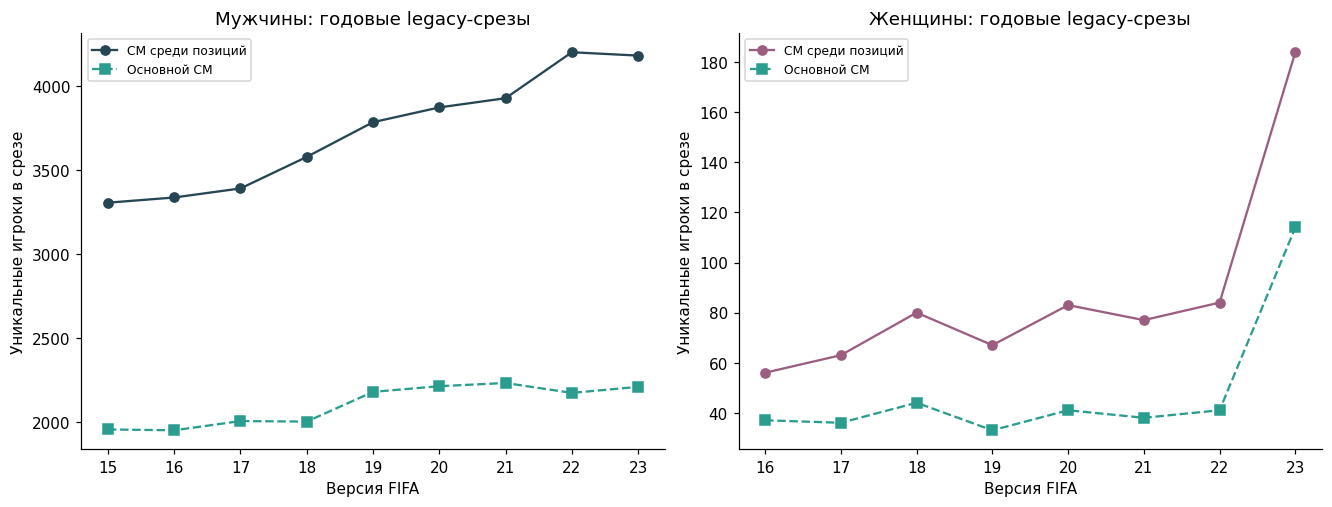

In [12]:
legacy_history = []
for sex, frame in [("male", male_legacy), ("female", female_legacy)]:
    for (version, date), group in frame.groupby(["fifa_version", "fifa_update_date"]):
        legacy_history.append({"sex": sex, "version": int(version), "date": pd.Timestamp(date),
                               "players": len(group), "cm": int(cm_mask(group).sum()),
                               "primary_cm": int(primary_cm_mask(group).sum())})
legacy_history = pd.DataFrame(legacy_history).sort_values(["sex", "version"])
display(legacy_history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax, sex, title in zip(axes, ["male", "female"], ["Мужчины", "Женщины"]):
    data = legacy_history.loc[legacy_history.sex.eq(sex)]
    ax.plot(data.version, data.cm, marker="o", color=COLORS[sex], label="CM среди позиций")
    ax.plot(data.version, data.primary_cm, marker="s", linestyle="--", color=COLORS["tm"], label="Основной CM")
    ax.set(title=f"{title}: годовые legacy-срезы", xlabel="Версия FIFA", ylabel="Уникальные игроки в срезе")
    ax.set_xticks(data.version)
    ax.legend(fontsize=8)
show_figure(fig, "04_cm_by_fifa_version")


### 6. Периоды наблюдений и календарь данных

Год версии FIFA не равен календарному году наблюдения. Основной выпуск FIFA 23 в этих данных датирован сентябрём 2022 года.

В Transfermarkt есть двухгодичные сезоны (`21/22`) и календарные годы (`2021`). Для cutoff 26.09.2022 итоги текущего сезона 22/23 и календарного 2022 года нельзя использовать как уже завершённый сезон. Для календарных лиг предыдущий завершённый сезон — 2021.


male_players.csv : 2014-08-29 — 2023-01-13 ; срезов: 558
female_players.csv : 2015-08-28 — 2023-01-13 ; срезов: 519
История оценок: 2003-12-14 — 2025-09-11


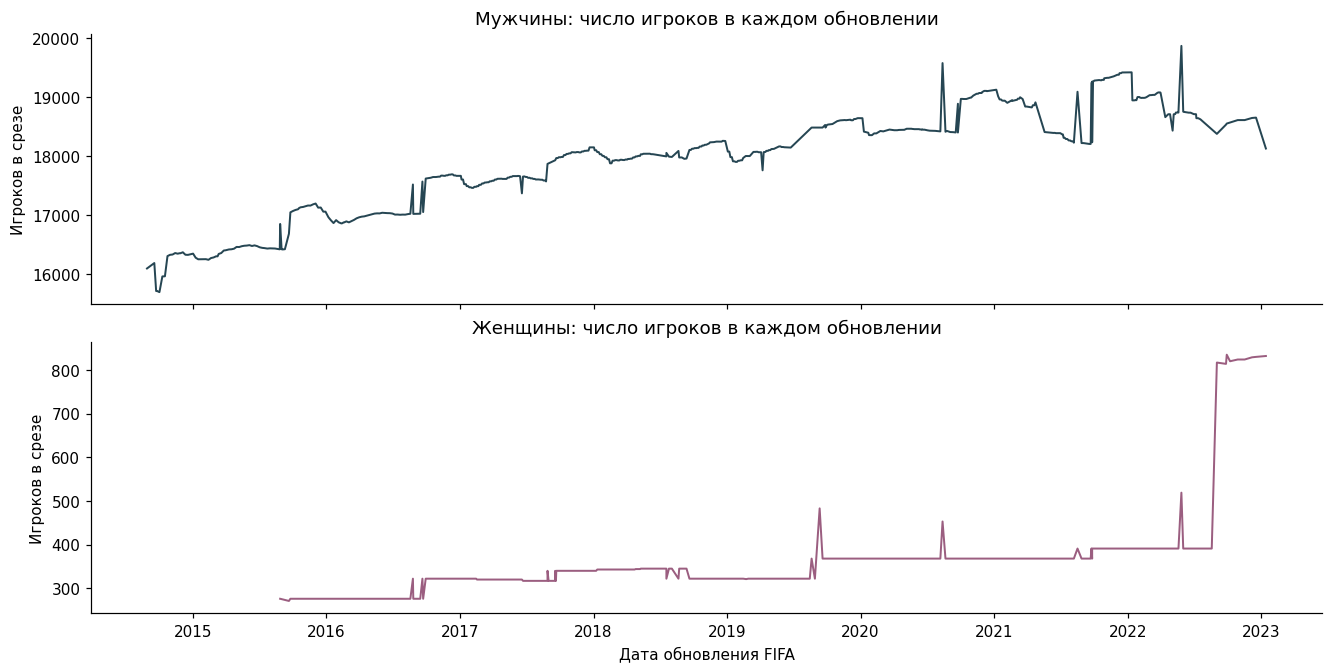

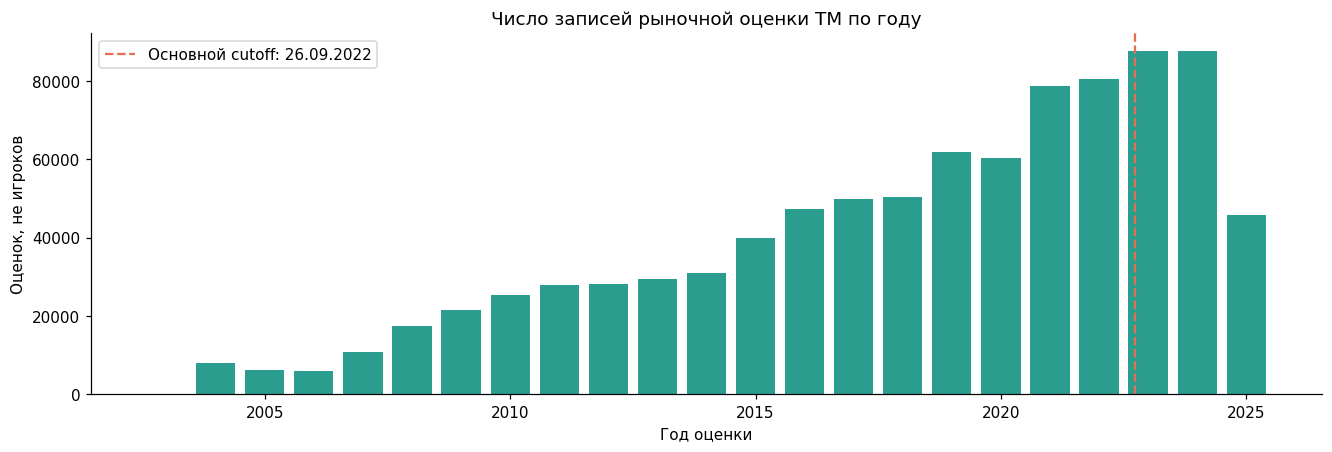

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout="constrained")
for ax, filename, color, title in [(axes[0], "male_players.csv", COLORS["male"], "Мужчины"),
                                   (axes[1], "female_players.csv", COLORS["female"], "Женщины")]:
    data = snapshot_tables[filename].copy()
    data["date"] = pd.to_datetime(data.fifa_update_date)
    data = data.sort_values("date")
    ax.plot(data.date, data.rows, color=color, linewidth=1.3)
    ax.set(title=f"{title}: число игроков в каждом обновлении", ylabel="Игроков в срезе")
    print(filename, ":", data.date.min().date(), "—", data.date.max().date(), "; срезов:", len(data))
axes[-1].set_xlabel("Дата обновления FIFA")
show_figure(fig, "05_fifa_observation_periods")

yearly_values = pd.to_datetime(values.date_unix, format="%Y-%m-%d").dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.bar(yearly_values.index, yearly_values.values, color=COLORS["tm"])
ax.set(title="Число записей рыночной оценки TM по году", xlabel="Год оценки", ylabel="Оценок, не игроков")
ax.axvline(2022.73, linestyle="--", color=COLORS["loss"], label="Основной cutoff: 26.09.2022")
ax.legend()
show_figure(fig, "06_tm_market_value_history")
print("История оценок:", values.date_unix.min(), "—", values.date_unix.max())


In [14]:
# Read season-level rows in chunks; retain only 21/22 rather than all 1.88M rows in RAM.
performance_profile = profile_by_file["player_performances.csv"]
performance_columns = ["player_id", "season_name", "competition_id", "team_id", "nb_in_group", "nb_on_pitch",
                       "goals", "assists", "minutes_played", "yellow_cards", "second_yellow_cards", "direct_red_cards", "penalty_goals"]
season_counts = Counter()
previous_season_parts = []
performance_rows = 0
with zipfile.ZipFile(archive_paths["transfermarkt"]) as archive:
    for chunk in pd.read_csv(archive.open(performance_profile["member"]), dtype=str, na_filter=False,
                             usecols=performance_columns, chunksize=100_000):
        season_counts.update(chunk.season_name.value_counts().to_dict())
        previous_season_parts.append(chunk.loc[chunk.season_name.eq("21/22")].copy())
        performance_rows += len(chunk)
assert performance_rows == performance_profile["rows"]
assert dict(season_counts) == performance_profile["categories"]["season_name"]
perf_previous = pd.concat(previous_season_parts, ignore_index=True)
del previous_season_parts
assert not perf_previous.duplicated(["player_id", "season_name", "competition_id", "team_id"]).any()

seasons = pd.DataFrame([{"season": name, "rows": count,
                         "calendar_type": "calendar_year" if "/" not in name else "two_year_season"}
                        for name, count in season_counts.items()])
display(seasons.sort_values(["calendar_type", "season"]).reset_index(drop=True))
print("Все 21/22:", len(perf_previous), "строк. Метка 1960:", season_counts["1960"], "; метка 2026:", season_counts["2026"])
print("Ранние и будущие метки — границы содержимого файла, а не доказательство надёжного покрытия этих лет.")


Все 21/22: 104402 строк. Метка 1960: 1 ; метка 2026: 177
Ранние и будущие метки — границы содержимого файла, а не доказательство надёжного покрытия этих лет.


,season,rows,calendar_type
0,1960,1,calendar_year
1,1975,1,calendar_year
2,1984,1,calendar_year
3,1985,3,calendar_year
4,1986,3,calendar_year
...,...,...,...
97,95/96,5158,two_year_season
98,96/97,6688,two_year_season
99,97/98,8803,two_year_season
100,98/99,10659,two_year_season


### 7. Проверка дат и невозможных значений

Проверяем формат, диапазон, дату до рождения и несовпадение года с меткой сезона. Дата окончания контракта после выгрузки допустима; будущая дата перехода может быть плановой. Такие флаги нельзя автоматически объявлять ошибками. Дата перехода 3026 года и травма до рождения требуют карантина.

`date_unix` в данном CSV — строка ISO-даты, а не Unix timestamp. `_last_modified_at` клубных таблиц даёт ориентир выгрузки 11–13.09.2025, но не историю момента публикации каждого показателя.


In [15]:
from audit_moneyball_quality import date_stats

date_audit = []
births = tm_profiles.set_index("player_id").date_of_birth
conflict_examples = []
quality_reference = read_json(REPORTS / "quality_findings.json")
for filename, date_columns in [("player_injuries.csv", ["from_date", "end_date"]),
                               ("transfer_history.csv", ["transfer_date"])]:
    frame = read_source("transfermarkt", filename, usecols=["player_id", "season_name", *date_columns])
    for column in date_columns:
        stats = date_stats(frame[column], anchor=EXTRACT_ANCHOR)
        dob = frame.player_id.map(births)
        before_birth = frame[column].ne("") & dob.notna() & dob.ne("") & frame[column].lt(dob.fillna(""))
        stats["date_before_player_birth"] = int(before_birth.sum())
        assert stats["date_before_player_birth"] == quality_reference[f"{filename}:{column}"]["date_before_player_birth"]
        date_audit.append({"file": filename, "column": column, **stats})
        if before_birth.any():
            example = frame.loc[before_birth].copy()
            example["date_of_birth"] = dob.loc[before_birth]
            conflict_examples.append(example)

    def first_year(label):
        first = label.split("/")[0]
        if not first.isdigit():
            return np.nan
        year = int(first)
        return year if len(first) == 4 else (2000 + year if year <= 40 else 1900 + year)

    first_date = date_columns[0]
    start_year = frame.season_name.map({s: first_year(s) for s in frame.season_name.unique()})
    date_year = pd.to_numeric(frame[first_date].str[:4], errors="coerce")
    mismatch = start_year.notna() & date_year.notna() & ~(date_year.eq(start_year) | date_year.eq(start_year + 1))
    assert int(mismatch.sum()) == quality_reference[f"{filename}:date_year_outside_season_years"]
    print(filename, ": дата вне двух годов метки сезона —", int(mismatch.sum()))
    if filename == "transfer_history.csv":
        display(frame.loc[frame.transfer_date.gt("2035-12-31")])
    else:
        display(frame.loc[frame.season_name.str.match(r"19\d\d/")].head(7))
    del frame

for column in ["date_of_birth", "joined", "contract_expires", "date_of_last_contract_extension", "date_of_death"]:
    date_audit.append({"file": "player_profiles.csv", "column": column,
                       **date_stats(tm_profiles[column], anchor=EXTRACT_ANCHOR)})
display(pd.DataFrame(date_audit))
display(pd.concat(conflict_examples, ignore_index=True))


player_injuries.csv : дата вне двух годов метки сезона — 253
transfer_history.csv : дата вне двух годов метки сезона — 656


,player_id,season_name,from_date,end_date
10634,1301,1910/11,2010-09-28,2010-10-18
18449,15854,1909/10,2009-09-29,2009-10-24
55363,2934,1910/11,2011-05-12,2011-05-17
63072,33317,1909/10,2009-09-10,2010-01-04
64634,33729,1909/10,2010-04-18,2010-04-28
77195,38887,1909/10,2009-08-01,2009-08-15
137496,89,1909/10,2009-11-10,2010-02-17


,player_id,season_name,transfer_date
1078490,954357,25/26,3026-06-30


,file,column,blank,non_iso,unparseable_iso,min_valid,max_valid,before_1950,after_extract_anchor,beyond_2035,date_before_player_birth
0,player_injuries.csv,from_date,22,0,0,1973-09-02,2025-12-22,0,2,0,1.0
1,player_injuries.csv,end_date,1523,0,0,1973-09-06,2026-09-01,0,390,0,1.0
2,transfer_history.csv,transfer_date,580,0,0,1900-07-01,3026-06-30,5,4193,1,3.0
3,player_profiles.csv,date_of_birth,1006,0,0,1952-02-13,2010-10-12,0,0,0,NaN
4,player_profiles.csv,joined,3382,0,0,1988-07-01,2025-09-13,0,0,0,NaN
5,player_profiles.csv,contract_expires,54005,0,0,2025-01-01,2035-06-30,0,36345,0,NaN
6,player_profiles.csv,date_of_last_contract_extension,84308,0,0,2015-07-31,2029-12-17,0,5,0,NaN
7,player_profiles.csv,date_of_death,92399,272,0,NaN,NaN,0,0,0,NaN


,player_id,season_name,from_date,end_date,date_of_birth,transfer_date
0,1085928,24/25,2004-01-21,2004-10-18,2006-09-02,NaN
1,1085928,24/25,2004-01-21,2004-10-18,2006-09-02,NaN
2,1182425,23/24,NaN,NaN,2007-01-02,2003-07-30
3,152806,1900/01,NaN,NaN,1972-12-05,1900-07-01
4,168567,1904/05,NaN,NaN,1977-07-24,1904-11-01


### 8. Сопоставление FIFA 23 ↔ Transfermarkt

В источниках разные пространства `player_id`. Для связи используются отдельные `fifa_id` и `tm_id`.

Принятое правило: точная дата рождения + точный нормализованный алиас (полное/короткое имя или slug), единственный кандидат и взаимно однозначная связь. Конечный `(ID)` в имени TM удаляется. Разница роста >10 см отправляется на проверку; это может быть ошибка измерения или изменение роста, а не обязательно другая личность. Клуб не обязан совпадать через несколько лет.

Нечёткие кандидаты **не принимаются автоматически**. Процент сопоставления ниже — покрытие выбранного правила, а не precision/recall: размеченного эталона нет.

Реализация: [scripts/audit_moneyball_join.py](../scripts/audit_moneyball_join.py).


In [16]:
wrong_id_join = male_release.merge(tm_profiles, on="player_id", suffixes=("_fifa", "_tm"))
wrong_id_summary = pd.DataFrame([{"method": "Прямой join по player_id", "pairs": len(wrong_id_join),
                                 "same_date_of_birth": int(wrong_id_join.dob.eq(wrong_id_join.date_of_birth).sum())}])
display(wrong_id_summary)
assert len(wrong_id_join) == 1581 and wrong_id_join.dob.eq(wrong_id_join.date_of_birth).sum() == 0
del wrong_id_join

from audit_moneyball_join import match, dated_values, aggregate_performance

def load_latest23(source, filename):
    cached_path = PROCESSED / f"{Path(filename).stem}_fifa23_latest.csv"
    profile = profile_by_file[filename]
    date = profile["fifa23_latest_date"]
    if cached_path.exists():
        result = pd.read_csv(cached_path, dtype=str, na_filter=False)
    else:
        print(f"Нет подготовленного среза {filename}; извлекаем последнюю дату потоково из архива.")
        pieces = []
        with zipfile.ZipFile(archive_paths[source]) as archive:
            for chunk in pd.read_csv(archive.open(profile["member"]), dtype=str, na_filter=False, chunksize=50_000):
                pieces.append(chunk.loc[chunk.fifa_version.eq("23") & chunk.fifa_update_date.eq(date)].copy())
        result = pd.concat(pieces, ignore_index=True)
    assert len(result) == profile["fifa23_latest_rows"]
    assert result.fifa_update_date.eq(date).all() and result.fifa_version.eq("23").all()
    assert result.player_id.is_unique
    return result

male_latest = load_latest23("fifa_male", "male_players.csv")
female_latest = load_latest23("fifa_female", "female_players.csv")
fifa_slices = {"male_legacy23": male_release, "female_legacy23": female_release,
               "male_players_fifa23_latest": male_latest, "female_players_fifa23_latest": female_latest}
match_rows, joined_slices, links_by_slice, review_by_slice = [], {}, {}, {}
join_reference = {row["snapshot"]: row for row in read_json(REPORTS / "join_summary.json")}
for name, frame in fifa_slices.items():
    links, review = match(frame, tm_profiles)
    assert links.fifa_id.is_unique and links.tm_id.is_unique
    joined = frame.rename(columns={"player_id": "fifa_id"}).merge(links, how="left", on="fifa_id", validate="one_to_one")
    assert len(joined) == len(frame)
    cutoff = frame.fifa_update_date.iloc[0]
    joined = dated_values(joined, values, cutoff)
    cm = cm_mask(joined)
    row = {"snapshot": name, "cutoff": cutoff, "players": len(frame), "cm": int(cm.sum()),
           "matched": len(links), "matched_pct": 100 * len(links)/len(frame),
           "cm_matched": int(joined.loc[cm, "tm_id"].notna().sum()),
           "cm_matched_pct": 100 * joined.loc[cm, "tm_id"].notna().mean(),
           "cm_valid_value": int(joined.loc[cm, "valid_market_value"].sum())}
    assert row["matched"] == join_reference[name]["matched"]
    assert row["cm_matched"] == join_reference[name]["cm_matched"]
    match_rows.append(row)
    joined_slices[name], links_by_slice[name], review_by_slice[name] = joined, links, review
    print(name, ": сопоставлено", row["matched"], "из", row["players"])
match_summary = pd.DataFrame(match_rows)
display(match_summary.round(2))


male_legacy23 : сопоставлено 13261 из 18533
female_legacy23 : сопоставлено 0 из 814
male_players_fifa23_latest : сопоставлено 13078 из 18127
female_players_fifa23_latest : сопоставлено 0 из 832


,method,pairs,same_date_of_birth
0,Прямой join по player_id,1581,0


,snapshot,cutoff,players,cm,matched,matched_pct,cm_matched,cm_matched_pct,cm_valid_value
0,male_legacy23,2022-09-26,18533,4184,13261,71.55,3057,73.06,2886
1,female_legacy23,2022-09-26,814,184,0,0.00,0,0.00,0
2,male_players_fifa23_latest,2023-01-13,18127,4076,13078,72.15,3021,74.12,2851
3,female_players_fifa23_latest,2023-01-13,832,196,0,0.00,0,0.00,0


Строки кандидатов могут повторять FIFA-игрока; это не число дополнительных подтверждённых связей.


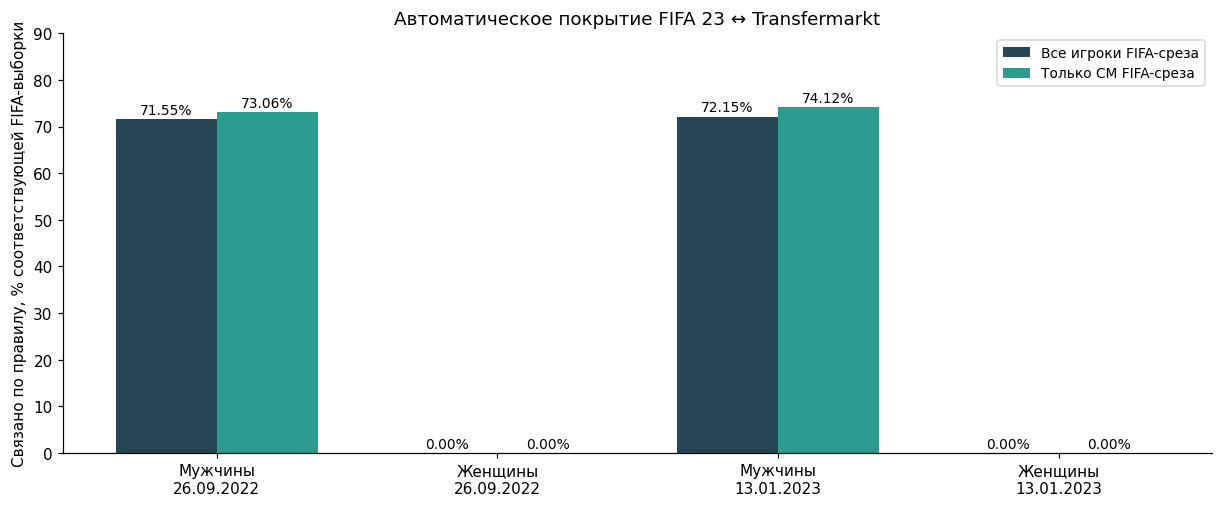

,candidate_rows
reason,
fuzzy_review_only,282
height_conflict_over_10cm,58
ambiguous_exact,1


,fifa_id,fifa_name,dob,reason,tm_candidates,tm_name,name_score
0,211990,Odisseas Vlachodimos,1994-04-26,fuzzy_review_only,124419,Odysseas Vlachodimos (124419),0.950000
1,227236,André-Franck Zambo Anguissa,1995-11-16,fuzzy_review_only,354361,Frank Anguissa (354361),0.981132
2,231936,Benjamin White,1997-10-08,fuzzy_review_only,335721,Ben White (335721),0.875000
3,234035,Álvaro Odriozola Arzalluz,1995-12-14,fuzzy_review_only,280730,Álvaro Odriozola (280730),0.960000
4,233959,Sebastián Villa Cano,1996-05-19,fuzzy_review_only,267152,Sebastian Musiolik (267152),0.727273
5,250723,Emmanuel Kouadio Koné,2001-05-17,fuzzy_review_only,624690,Manu Koné (624690),0.772727
6,210648,Ahmed Elsayed Ali Elsayed Hegazy,1991-01-25,fuzzy_review_only,111524,Ahmed Hegazy (111524),0.916667
7,213577,Antonio José Rodríguez Díaz,1992-02-21,fuzzy_review_only,262365,Antonio Puertas (262365),0.814815
8,240915,Juan Miranda González,2000-01-19,ambiguous_exact,341227;412376,NaN,NaN
9,244778,Francisco António Machado Mota Castro Trincão,1999-12-29,fuzzy_review_only,412669,Francisco Trincão (412669),0.967742


In [17]:
labels = ["Мужчины\n26.09.2022", "Женщины\n26.09.2022", "Мужчины\n13.01.2023", "Женщины\n13.01.2023"]
x = np.arange(len(match_summary))
fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
ax.bar(x - .18, match_summary.matched_pct, width=.36, color=COLORS["male"], label="Все игроки FIFA-среза")
ax.bar(x + .18, match_summary.cm_matched_pct, width=.36, color=COLORS["tm"], label="Только CM FIFA-среза")
for positions, values_to_label in [(x - .18, match_summary.matched_pct), (x + .18, match_summary.cm_matched_pct)]:
    for xpos, pct in zip(positions, values_to_label):
        ax.text(xpos, pct + 1.1, f"{pct:.2f}%", ha="center", fontsize=9)
ax.set_xticks(x, labels)
ax.set_ylim(0, 90)
ax.set_ylabel("Связано по правилу, % соответствующей FIFA-выборки")
ax.set_title("Автоматическое покрытие FIFA 23 ↔ Transfermarkt")
ax.legend(loc="upper right", fontsize=9)
show_figure(fig, "07_entity_match_coverage")

display(review_by_slice["male_legacy23"].reason.value_counts().rename_axis("reason").to_frame("candidate_rows"))
display(review_by_slice["male_legacy23"].head(10))
print("Строки кандидатов могут повторять FIFA-игрока; это не число дополнительных подтверждённых связей.")


### 9. Историческое объединение стоимости и потери выборки

Берётся **последняя оценка на дату или раньше cutoff**, а не ближайшая дата с любой стороны. Затем `value > 0` и давность ≤365 дней. Порог 365 дней — зафиксированное допущение v1; ниже показана его чувствительность.

Последний/current файл TM не подходит как историческая цена. Полная история присоединяется только после выбора одной оценки на игрока, чтобы не размножить FIFA-строки.

В TM CSV нет валютной колонки. Сохраняем имя `tm_market_value` и единицы источника, не добавляя неподтверждённый суффикс `_eur`.


In [18]:
history_last = values.sort_values(["player_id", "date_unix"]).drop_duplicates("player_id", keep="last")
latest_check = latest_values.merge(history_last, on="player_id", validate="one_to_one", suffixes=("_latest", "_history"))
assert latest_check.date_unix_latest.eq(latest_check.date_unix_history).all()
assert pd.to_numeric(latest_check.value_latest).eq(pd.to_numeric(latest_check.value_history)).all()
print("Latest-файл совпадает с последними строками истории:", len(latest_check), "игроков.")
print("Его оценок позже основного cutoff:", latest_values.date_unix.gt(CUTOFF).sum())

joined = joined_slices["male_legacy23"]
selected = joined.loc[cm_mask(joined)].copy()
assert selected.fifa_id.is_unique
known_date = selected.market_value_date.notna()
assert selected.loc[known_date, "market_value_date"].le(CUTOFF).all()
assert selected.loc[known_date, "market_value_age_days"].ge(0).all()

conditions = [selected.tm_id.isna(), selected.tm_id.notna() & selected.tm_market_value.isna(),
              selected.tm_market_value.eq(0), selected.tm_market_value.gt(0) & selected.market_value_age_days.gt(365),
              selected.valid_market_value]
statuses = ["Нет связи с TM", "Нет исторической оценки", "Оценка равна нулю", "Положительная оценка старше 365 дней", "Годная историческая оценка"]
status_coverage = sum(mask.astype(int) for mask in conditions)
assert status_coverage.eq(1).all(), "Причины должны быть взаимно исключающими и покрывать всех CM."
selected["availability_status"] = np.select(conditions, statuses, default="ERROR")
attrition = selected.availability_status.value_counts().reindex(statuses)
display(attrition.rename_axis("status").to_frame("cm"))
assert attrition.sum() == 4184 and attrition.iloc[-1] == 2886

sensitivity = pd.DataFrame({"max_age_days": [90, 180, 365, 730]})
sensitivity["eligible_cm"] = [int((selected.tm_market_value.gt(0) & selected.market_value_age_days.le(days)).sum())
                             for days in sensitivity.max_age_days]
display(sensitivity)


Latest-файл совпадает с последними строками истории: 69441 игроков.
Его оценок позже основного cutoff: 48468


,cm
status,
Нет связи с TM,1127
Нет исторической оценки,95
Оценка равна нулю,7
Положительная оценка старше 365 дней,69
Годная историческая оценка,2886


,max_age_days,eligible_cm
0,90,904
1,180,2760
2,365,2886
3,730,2913


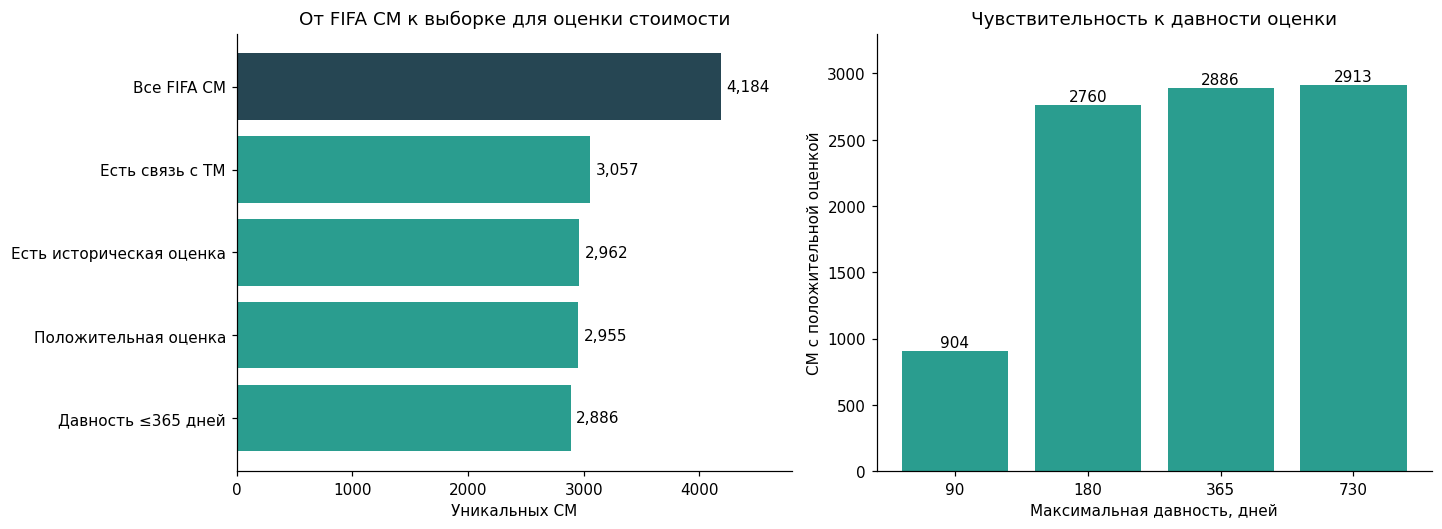

In [19]:
stage_labels = ["Все FIFA CM", "Есть связь с TM", "Есть историческая оценка", "Положительная оценка", "Давность ≤365 дней"]
stage_counts = [len(selected), int(selected.tm_id.notna().sum()), int(selected.tm_market_value.notna().sum()),
                int(selected.tm_market_value.gt(0).sum()), int(selected.valid_market_value.sum())]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7), layout="constrained")
axes[0].barh(stage_labels, stage_counts, color=[COLORS["male"]] + [COLORS["tm"]] * 4)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 4800)
axes[0].set_title("От FIFA CM к выборке для оценки стоимости")
for i, count in enumerate(stage_counts):
    axes[0].text(count + 45, i, f"{count:,}", va="center")
axes[0].set_xlabel("Уникальных CM")
axes[1].bar(sensitivity.max_age_days.astype(str), sensitivity.eligible_cm, color=COLORS["tm"])
axes[1].set(title="Чувствительность к давности оценки", xlabel="Максимальная давность, дней", ylabel="CM с положительной оценкой")
for i, count in enumerate(sensitivity.eligible_cm):
    axes[1].text(i, count + 30, str(count), ha="center")
axes[1].set_ylim(0, 3300)
show_figure(fig, "08_value_join_attrition")


### 10. Покрытие, смещение и доступность статистики на 90 минут

Сопоставленные игроки не являются случайной подвыборкой. Проверяем рейтинг, возраст и лиги. Названия лиг неоднозначны: контекст задаём категориальным FIFA `league_id`.

Для проверки минут суммируются записи одного завершённого сезона по командам и соревнованиям. Если хотя бы одна составляющая отсутствует, итог считается неизвестным. Неизвестные минуты не заменяются нулём. Это консервативная оценка покрытия **полного 21/22**, а не числа игроков хотя бы с одной известной записью минут.


,cm,overall_mean,overall_median,age_mean
matched,,,,
False,1127,63.34,64.0,25.00
True,3057,67.21,67.0,25.19


,different_league_ids
league_name,
Bundesliga,2
Premier League,3
Primera Division,4
Pro League,2
Serie A,2
Super League,4


,,cm,matched,valued,matched_pct,valued_pct
league_id,league_name,,,,,
353,Liga Profesional,184,96,96,52.2,52.2
14,Championship,175,165,148,94.3,84.6
39,Major League Soccer,172,151,151,87.8,87.8
13,Premier League,150,148,130,98.7,86.7
32,Serie B,150,134,134,89.3,89.3
61,League Two,150,112,16,74.7,10.7
53,La Liga,149,139,138,93.3,92.6
60,League One,147,134,122,91.2,83.0
31,Serie A,147,137,137,93.2,93.2


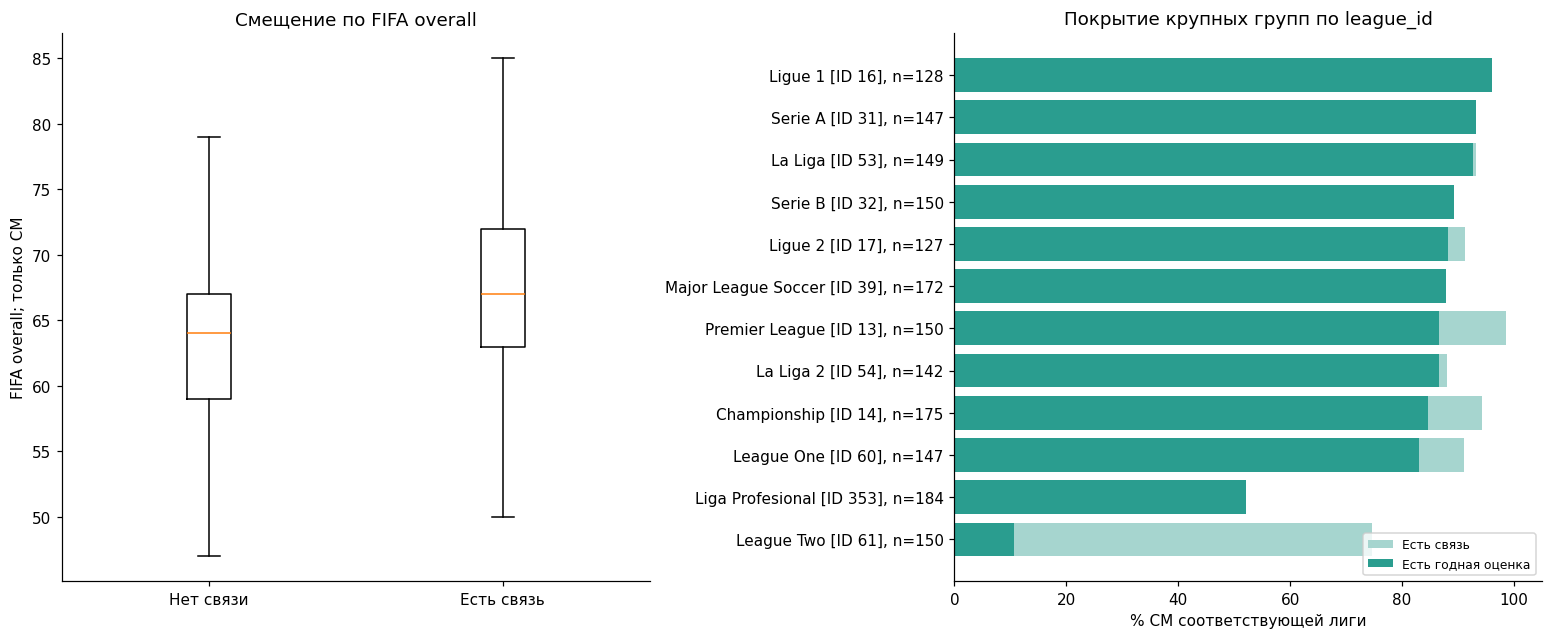

In [20]:
selected["overall_numeric"] = pd.to_numeric(selected.overall)
selected["age_numeric"] = pd.to_numeric(selected.age)
bias = selected.assign(matched=selected.tm_id.notna()).groupby("matched").agg(
    cm=("fifa_id", "size"), overall_mean=("overall_numeric", "mean"), overall_median=("overall_numeric", "median"),
    age_mean=("age_numeric", "mean"))
display(bias.round(2))

league_name_collisions = male_release.groupby("league_name").league_id.nunique().loc[lambda s: s.gt(1)]
display(league_name_collisions.rename("different_league_ids").to_frame())
league_coverage = selected.groupby(["league_id", "league_name"], dropna=False).agg(
    cm=("fifa_id", "size"), matched=("tm_id", "count"), valued=("valid_market_value", "sum"))
league_coverage["matched_pct"] = 100 * league_coverage.matched / league_coverage.cm
league_coverage["valued_pct"] = 100 * league_coverage.valued / league_coverage.cm
display(league_coverage.sort_values("cm", ascending=False).head(15).round(1))

top_leagues = league_coverage.sort_values("cm", ascending=False).head(12).sort_values("valued_pct")
league_labels = [f"{name} [ID {identifier}], n={int(n)}" for (identifier, name), n in zip(top_leagues.index, top_leagues.cm)]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.7), layout="constrained")
axes[0].boxplot([selected.loc[selected.tm_id.isna(), "overall_numeric"], selected.loc[selected.tm_id.notna(), "overall_numeric"]],
                showfliers=False)
axes[0].set_xticks([1, 2], ["Нет связи", "Есть связь"])
axes[0].set(title="Смещение по FIFA overall", ylabel="FIFA overall; только CM")
axes[1].barh(league_labels, top_leagues.matched_pct, color="#a6d5cf", label="Есть связь")
axes[1].barh(league_labels, top_leagues.valued_pct, color=COLORS["tm"], label="Есть годная оценка")
axes[1].set_xlim(0, 105)
axes[1].set(title="Покрытие крупных групп по league_id", xlabel="% CM соответствующей лиги")
axes[1].legend(fontsize=8)
show_figure(fig, "09_selection_bias")


,field,all_cm_available,valued_cm_available,valued_cm_pct
0,prev_nb_on_pitch,2615,2455,85.07
1,prev_minutes_played,238,231,8.00
2,prev_goals_p90,190,186,6.44
3,prev_assists_p90,190,186,6.44


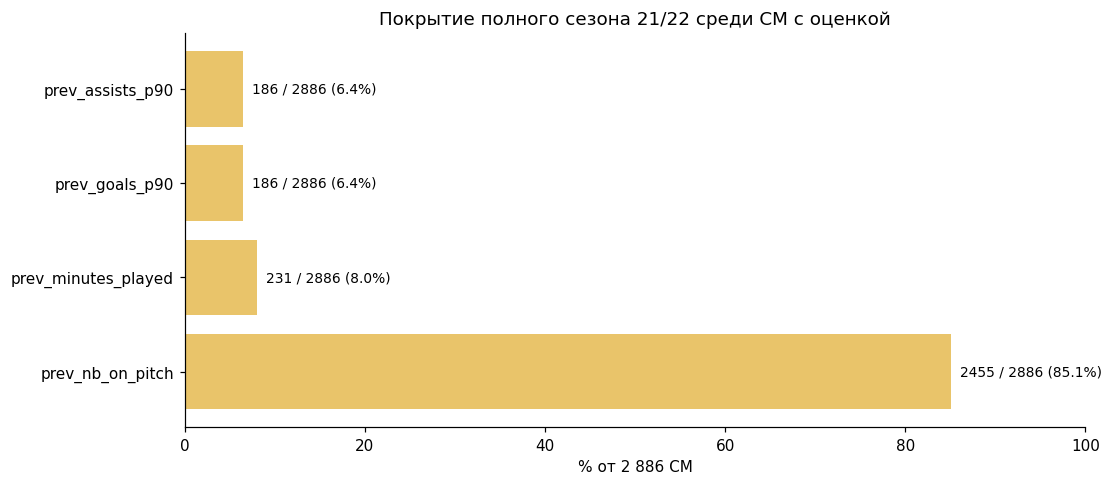

In [21]:
past = aggregate_performance(perf_previous, "21/22")
with_performance = selected.merge(past, on="tm_id", how="left", validate="many_to_one")
assert len(with_performance) == len(selected)
valued = with_performance.valid_market_value
performance_coverage = pd.DataFrame([
    {"field": field, "all_cm_available": int(with_performance[field].notna().sum()),
     "valued_cm_available": int(with_performance.loc[valued, field].notna().sum()),
     "valued_cm_pct": 100 * with_performance.loc[valued, field].notna().mean()}
    for field in ["prev_nb_on_pitch", "prev_minutes_played", "prev_goals_p90", "prev_assists_p90"]
])
display(performance_coverage.round(2))
assert with_performance.loc[valued, "prev_minutes_played"].notna().sum() == 231
assert with_performance.loc[valued, "prev_goals_p90"].notna().sum() == 186

fig, ax = plt.subplots(figsize=(10, 4.3), layout="constrained")
ax.barh(performance_coverage.field, performance_coverage.valued_cm_pct, color=COLORS["warning"])
ax.set_xlim(0, 100)
for i, row in performance_coverage.iterrows():
    ax.text(row.valued_cm_pct + 1, i, f"{int(row.valued_cm_available)} / {int(valued.sum())} ({row.valued_cm_pct:.1f}%)", va="center", fontsize=9)
ax.set(title="Покрытие полного сезона 21/22 среди CM с оценкой", xlabel="% от 2 886 CM")
show_figure(fig, "10_previous_season_coverage")


### 11. Проверка и фиксация Feature Set v1

**Сходство:** 18 детальных игровых атрибутов FIFA. **Оценка стоимости:** те же 18 + 5 числовых и 4 категориальных поля = 27 исходных входов. После one-hot размерность увеличится.

Входы выбираются строго по allowlist [config/feature_set_v1.json](../config/feature_set_v1.json). Не использовать подход «все колонки, кроме y»: так в модель попадут цены, имена и информация из будущего.

Отбор v1 основан на покрытии и содержании. Корреляции помогают обнаружить дублирующие признаки, но не доказывают предсказательную полезность. Подбор весов, обучение и абляции относятся к следующим этапам.


In [22]:
contract = read_json(ROOT / "config/feature_set_v1.json")
CORE = contract["similarity_features"]
VALUE_NUMERIC = contract["valuation_additional_numeric_features"]
VALUE_CATEGORICAL = contract["valuation_additional_categorical_features"]
VALUE_FEATURES = CORE + VALUE_NUMERIC + VALUE_CATEGORICAL
assert len(CORE) == len(set(CORE)) == 18
assert len(VALUE_FEATURES) == len(set(VALUE_FEATURES)) == 27
display(pd.DataFrame([{"block": block, "features": ", ".join(features)}
                      for block, features in contract["similarity_feature_groups"].items()]))
display(pd.DataFrame({"numeric_additional": pd.Series(VALUE_NUMERIC), "categorical_additional": pd.Series(VALUE_CATEGORICAL)}))

X_core = selected[CORE].apply(pd.to_numeric, errors="coerce")
core_stats = X_core.describe().T
core_stats["missing"] = X_core.isna().sum()
core_stats["nunique"] = X_core.nunique()
display(core_stats.round(2))
assert X_core.notna().all().all()
assert X_core.ge(1).all().all() and X_core.le(99).all().all()
assert X_core.nunique().gt(1).all()

history_feature_coverage = []
for version, frame in male_legacy.groupby("fifa_version"):
    data = frame.loc[cm_mask(frame), CORE].apply(pd.to_numeric, errors="coerce")
    history_feature_coverage.append({"fifa_version": int(version), "cm": len(data),
                                     "complete_core": int(data.notna().all(axis=1).sum()),
                                     "missing_features": ", ".join(data.columns[data.isna().any()])})
display(pd.DataFrame(history_feature_coverage).sort_values("fifa_version"))
print("Для неизменных 18 X в legacy пригоден период с FIFA 17 / 20.09.2016; composure не переносить из будущего назад.")


Для неизменных 18 X в legacy пригоден период с FIFA 17 / 20.09.2016; composure не переносить из будущего назад.


,block,features
0,passing,"attacking_short_passing, skill_long_passing, m..."
1,ball_control,"skill_ball_control, skill_dribbling"
2,mobility,"movement_agility, movement_balance, movement_a..."
3,decisions,"movement_reactions, mentality_composure"
4,physical,"power_stamina, power_strength, mentality_aggre..."
5,defending,"mentality_interceptions, defending_marking_awa..."
6,long_shots,power_long_shots


,numeric_additional,categorical_additional
0,age_at_cutoff,preferred_foot
1,height_cm,work_rate_attack
2,weight_kg,work_rate_defence
3,weak_foot,league_id
4,league_level,NaN


,count,mean,std,min,25%,50%,75%,max,missing,nunique
attacking_short_passing,4184.0,68.44,6.95,30.0,64.0,68.0,73.0,93.0,0,54
skill_long_passing,4184.0,65.43,7.60,22.0,61.0,65.0,70.0,93.0,0,61
mentality_vision,4184.0,64.23,8.55,20.0,59.0,64.0,70.0,94.0,0,63
skill_ball_control,4184.0,67.00,7.56,28.0,62.0,67.0,72.0,92.0,0,55
skill_dribbling,4184.0,64.90,8.09,24.0,60.0,65.0,70.0,92.0,0,61
movement_agility,4184.0,68.94,9.43,30.0,63.0,70.0,75.0,94.0,0,65
movement_balance,4184.0,70.47,9.95,30.0,65.0,71.0,77.0,95.0,0,65
movement_reactions,4184.0,63.62,8.08,32.0,58.0,64.0,69.0,93.0,0,57
mentality_composure,4184.0,62.96,9.76,32.0,57.0,64.0,70.0,94.0,0,59
power_stamina,4184.0,70.74,11.37,30.0,64.0,72.0,79.0,95.0,0,65


,fifa_version,cm,complete_core,missing_features
0,15,3307,0,mentality_composure
1,16,3338,0,mentality_composure
2,17,3392,3392,
3,18,3580,3580,
4,19,3787,3787,
5,20,3875,3875,
6,21,3930,3930,
7,22,4204,4204,
8,23,4184,4184,


Пар с |Spearman rho| ≥ 0.95: 0


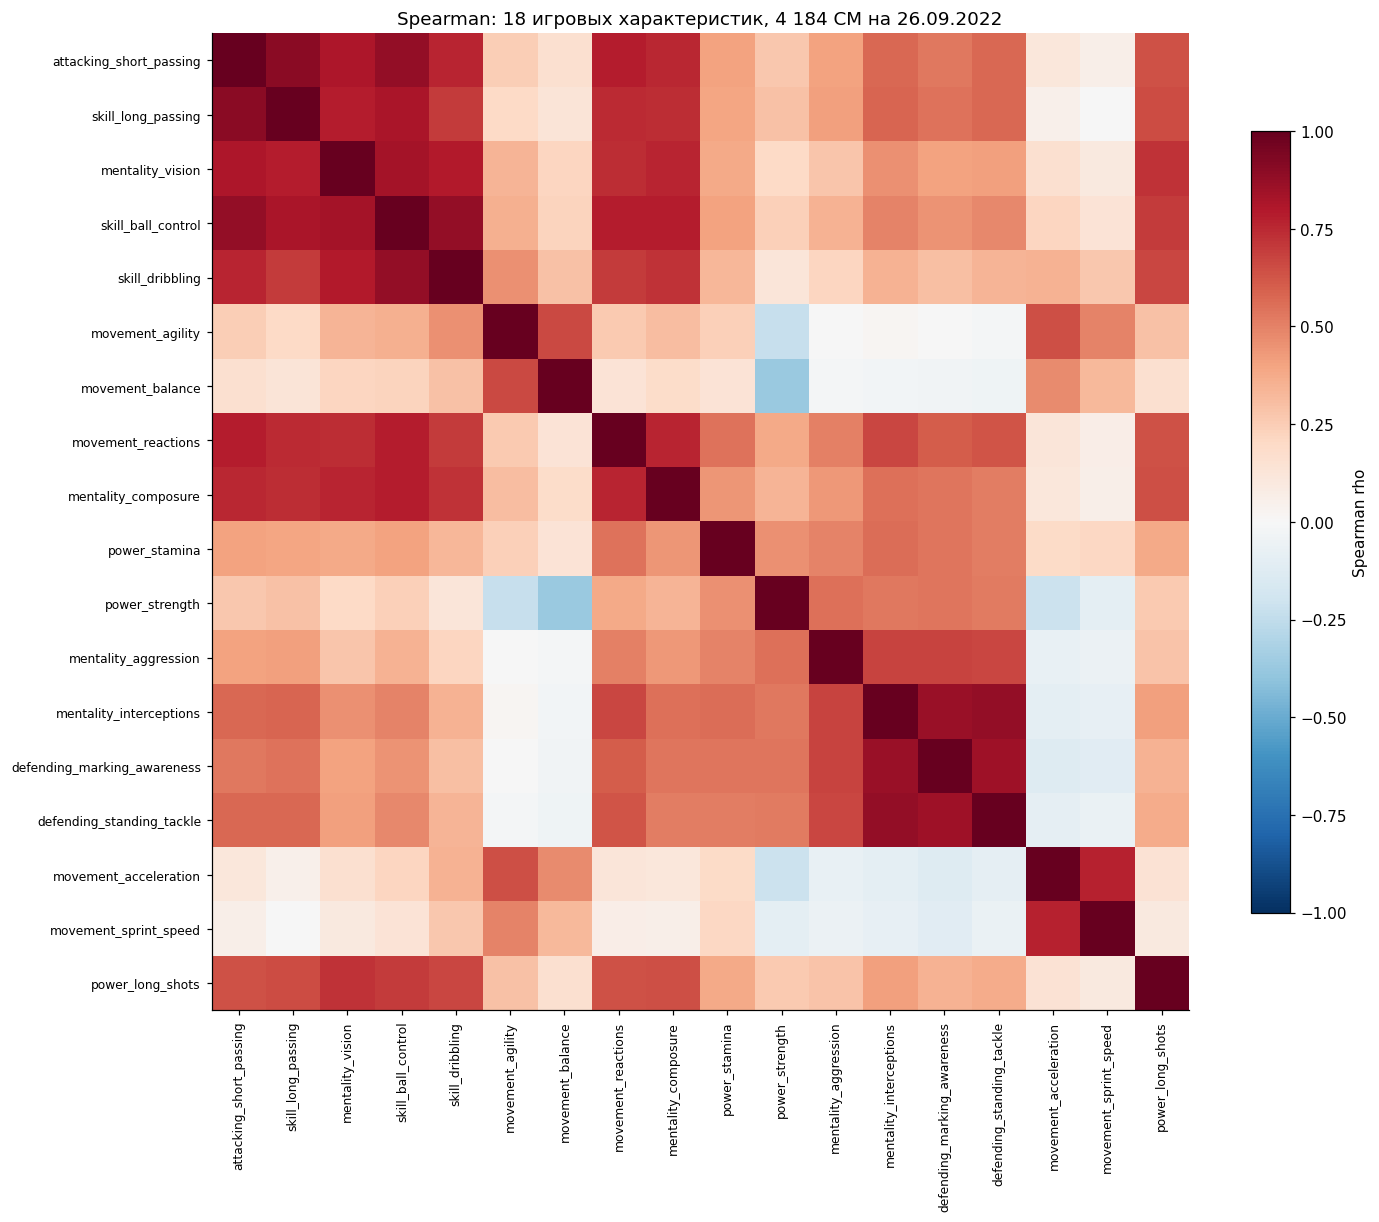

In [23]:
corr = X_core.corr(method="spearman")
upper_triangle = np.triu(np.ones(corr.shape, dtype=bool), k=1)
high_corr = corr.where(upper_triangle).stack().loc[lambda s: s.abs().ge(.95)]
print("Пар с |Spearman rho| ≥ 0.95:", len(high_corr))

fig, ax = plt.subplots(figsize=(13, 11), layout="constrained")
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(CORE)), CORE, rotation=90, fontsize=8)
ax.set_yticks(range(len(CORE)), CORE, fontsize=8)
ax.set_title("Spearman: 18 игровых характеристик, 4 184 CM на 26.09.2022")
fig.colorbar(image, ax=ax, label="Spearman rho", shrink=.8)
show_figure(fig, "11_core_feature_correlations")


X_similarity: (4184, 18) ; X_value до кодирования: (2886, 27)
y: log1p(tm_market_value), положительные исторические оценки в единицах источника.
Пропуски league_id → UNKNOWN; league_level → медиана только train-fold. В Step 1 imputer/scaler не обучаются.


,missing_before_preprocessing
attacking_short_passing,0
skill_long_passing,0
mentality_vision,0
skill_ball_control,0
skill_dribbling,0
movement_agility,0
movement_balance,0
movement_reactions,0
mentality_composure,0
power_stamina,0


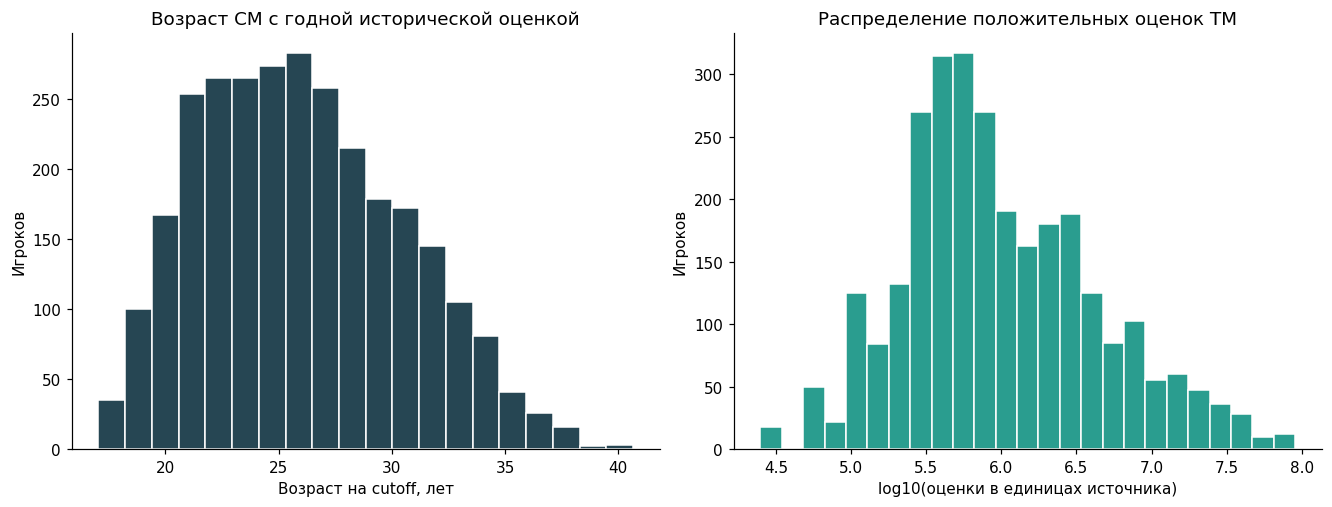

In [24]:
training_view = selected.loc[selected.valid_market_value].copy()
training_view["age_at_cutoff"] = (pd.Timestamp(CUTOFF) - pd.to_datetime(training_view.dob)).dt.days / 365.2425
work_rate = training_view.work_rate.str.split("/", expand=True)
training_view["work_rate_attack"], training_view["work_rate_defence"] = work_rate[0], work_rate[1]
training_view["target_log1p_tm_value"] = np.log1p(training_view.tm_market_value)
X_value = training_view[VALUE_FEATURES].replace("", np.nan)

display(X_value.isna().sum().rename("missing_before_preprocessing").to_frame())
print("X_similarity:", X_core.shape, "; X_value до кодирования:", X_value.shape)
print("y: log1p(tm_market_value), положительные исторические оценки в единицах источника.")
print("Пропуски league_id → UNKNOWN; league_level → медиана только train-fold. В Step 1 imputer/scaler не обучаются.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
axes[0].hist(training_view.age_at_cutoff, bins=20, color=COLORS["male"], edgecolor="white")
axes[0].set(title="Возраст CM с годной исторической оценкой", xlabel="Возраст на cutoff, лет", ylabel="Игроков")
axes[1].hist(np.log10(training_view.tm_market_value), bins=25, color=COLORS["tm"], edgecolor="white")
axes[1].set(title="Распределение положительных оценок TM", xlabel="log10(оценки в единицах источника)", ylabel="Игроков")
show_figure(fig, "12_age_and_value_distributions")


### 12. Итоговые проверки и выводы для следующего этапа

**Исключить из X:** записанную стоимость и её прокси (`value_eur`, `wage_eur`, `release_clause_eur`, transfer fee), сводные overall/potential/reputation, шесть агрегатов вместе с детальными атрибутами, GK-показатели, текущие TM клуб/позицию/контракт, накопленные данные сборных и партнёров без временного окна. `overall` оставить только для отдельного рейтинг-бейзлайна.

**Обязательные ограничения:**

- Временной join использует только оценки с датой ≤ cutoff, положительным значением и давностью ≤365 дней.
- Данные FIFA — игровые экспертные оценки, а не независимые матчевые события.
- Женские записи не смешиваются с мужскими; отсутствие найденных связей не доказывает отсутствие женщин во всём TM.
- Профили и история могли быть исправлены задним числом. Без knowledge-time версий это ретроспективный срез, а не доказанно точная реконструкция всей доступной тогда информации.
- Итоги 21/22 исследованы для покрытия; сезонная статистика, per-90, травмы и остаток контракта не входят в обязательный v1.
- Для последующего моделирования — разбиение по игрокам, в панели также по времени; encoder/scaler/imputer обучать внутри train. Сходство на тех же X не является независимой оценкой успеха.

Подробные результаты: [отчёт](../docs/data_profiling.md), [словарь столбцов](../docs/data_dictionary.md), [спецификация признаков](../docs/feature_set.md). Сырые данные и выгрузки игроков остаются в gitignored `data/processed/`; графики встроены в notebook.


In [25]:
metadata_columns = ["fifa_id", "tm_id", "fifa_update_date", "market_value_date", "market_value_age_days"]
target_columns = ["tm_market_value", "target_log1p_tm_value"]
assert training_view.fifa_id.is_unique and training_view.tm_id.is_unique
assert len(training_view) == 2886
assert training_view.tm_market_value.gt(0).all()
assert training_view.market_value_date.le(CUTOFF).all()
assert training_view.market_value_age_days.between(0, 365).all()
assert np.allclose(training_view.target_log1p_tm_value, np.log1p(training_view.tm_market_value))
assert X_value[CORE].notna().all().all()
assert X_value["league_id"].isna().sum() == 7 and X_value["league_level"].isna().sum() == 7
assert not set(VALUE_FEATURES) & set(contract["excluded_as_model_inputs"]["price_proxies"])

prepared_path = PROCESSED / "moneyball_cm_2022-09-26_training.csv"
if prepared_path.exists():
    prepared = pd.read_csv(prepared_path, dtype={"fifa_id": str, "tm_id": str, "league_id": str})
    assert set(prepared.columns) == set(VALUE_FEATURES + metadata_columns + target_columns)
    expected = training_view.set_index("fifa_id").sort_index()
    observed = prepared.set_index("fifa_id").sort_index()
    assert observed.index.equals(expected.index)
    assert observed.tm_id.equals(expected.tm_id)
    assert np.allclose(observed.tm_market_value, expected.tm_market_value)

checks = pd.DataFrame([
    ["SHA-256 трёх исходных архивов", True],
    ["CRC32 и схемы 19 CSV совпадают с полным профилем", True],
    ["Независимый пересчёт 18 CSV выполнен", len(independent_counts) == 18],
    ["Суммы исторических срезов совпадают с полными таблицами", True],
    ["CM: 4 184 уникальных игрока с полными 18 X", len(X_core) == 4184 and X_core.notna().all().all()],
    ["Связь FIFA ↔ TM взаимно однозначная", links_by_slice["male_legacy23"].tm_id.is_unique],
    ["Датированный join не увеличил число FIFA-игроков", len(joined) == len(male_release)],
    ["Будущие оценки исключены из 2 886 целевых строк", training_view.market_value_date.le(CUTOFF).all()],
    ["Feature Set: 18 / 27 исходных входов", len(CORE) == 18 and len(VALUE_FEATURES) == 27],
], columns=["check", "passed"])
if RECHECK_SMALL_FILES:
    assert checks.passed.all()
else:
    assert checks.loc[~checks["check"].str.startswith("Независимый"), "passed"].all()
display(checks)
display(Markdown(f"**Результат Step 1:** {len(X_core):,} CM × 18 игровых признаков; "
                 f"{len(X_value):,} CM × 27 исходных признаков для оценки стоимости. "
                 f"Построено {len(figure_paths)} графиков. Обучение моделей не выполнялось."))


,check,passed
0,SHA-256 трёх исходных архивов,True
1,CRC32 и схемы 19 CSV совпадают с полным профилем,True
2,Независимый пересчёт 18 CSV выполнен,True
3,Суммы исторических срезов совпадают с полными ...,True
4,CM: 4 184 уникальных игрока с полными 18 X,True
5,Связь FIFA ↔ TM взаимно однозначная,True
6,Датированный join не увеличил число FIFA-игроков,True
7,Будущие оценки исключены из 2 886 целевых строк,True
8,Feature Set: 18 / 27 исходных входов,True


**Результат Step 1:** 4,184 CM × 18 игровых признаков; 2,886 CM × 27 исходных признаков для оценки стоимости. Построено 12 графиков. Обучение моделей не выполнялось.